# 00 · Auditoría del panel

**Pregunta:** ¿el panel `panel_provincia_anual.csv` sirve para responder a lo que promete el README?

Este notebook no analiza vivienda: revisa el dato que alimenta el análisis. Una fila por tipo de vivienda (total, nueva, usada), territorio y año, con el precio, la renta del hogar y los años de renta necesarios para comprar 90 m².

Se comprueban cuatro cosas:

1. Que la estructura es la esperada.
2. Dónde hay huecos, de precio y de renta.
3. Qué tan sólidas son las medias anuales.
4. Si la métrica tiene valores imposibles.

Los huecos no se rellenan: se declaran.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import BoundaryNorm, ListedColormap

# El import de src/ funciona tanto si Jupyter se lanza desde la raíz del
# proyecto como desde notebooks/.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (  # noqa: E402
    ADRH_KNOWN_GAPS,
    ADRH_YEARS,
    FIGURES_DIR,
    INCOME_END_YEAR,
    INCOME_START_YEAR,
    NATIONAL_CODE,
    PRICE_END_YEAR,
    PROCESSED_DIR,
    PROVINCES,
    QUARTERS_PER_YEAR,
)

pd.set_option("display.width", 110)
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 150,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Sin dtype, "04" se convierte en 4 y "00" en 0: el cruce por provincia deja
# de casar. Se lee siempre con el código como texto.
panel = pd.read_csv(
    PROCESSED_DIR / "panel_provincia_anual.csv",
    dtype={"province_code": str},
)

KIND_LABELS = {"total": "Vivienda total", "nueva": "Nueva", "usada": "Usada"}

# "00" es la convención del proyecto para España, no un código INE.
CODES = [NATIONAL_CODE, *PROVINCES]


def territory(code):
    """Nombre para mostrar. La clave sigue siendo el código INE."""
    return "España" if code == NATIONAL_CODE else PROVINCES[code]

## 1 · Estructura

Debe haber una fila por tipo de vivienda, territorio y año: 53 territorios (52 provincias y España) y tres series con ventanas distintas. El precio empieza en 2007; la renta, en 2015, así que la métrica solo existe en la intersección.

In [2]:
print(f"Filas: {len(panel):,} | columnas: {panel.shape[1]}".replace(",", "."))
print(f"Territorios: {panel['province_code'].nunique()}")
print(f"Años: {panel['year'].min()}-{panel['year'].max()}")
print(f"2026 dentro del panel (debe ser False): {PRICE_END_YEAR in set(panel['year'])}")
print(f"Claves duplicadas (tipo, territorio, año): {panel.duplicated(['kind', 'province_code', 'year']).sum()}")

summary = (
    panel.groupby("kind")
    .agg(
        rows=("year", "size"),
        territories=("province_code", "nunique"),
        first_year=("year", "min"),
        last_year=("year", "max"),
        with_price=("price_nominal_eur_m2", "count"),
        with_income=("net_income_household_eur", "count"),
        with_metric=("years_90m2", "count"),
    )
    .rename(index=KIND_LABELS)
)
summary

Filas: 2.703 | columnas: 10
Territorios: 53
Años: 2007-2025
2026 dentro del panel (debe ser False): False
Claves duplicadas (tipo, territorio, año): 0


,rows,territories,first_year,last_year,with_price,with_income,with_metric
kind,,,,,,,
Nueva,848,53,2010,2025,811,512,486
Vivienda total,1007,53,2007,2025,1007,512,512
Usada,848,53,2010,2025,848,512,512


In [3]:
# IPC 2025 = 100, así que ese año real y nominal deben coincidir exactamente.
# Los nulos de vivienda nueva se quedan fuera: NaN == NaN siempre es False.
last = panel[panel["year"] == 2025].dropna(subset=["price_real_eur_m2"])
print(f"Filas de 2025 con precio: {len(last)} de {len(panel[panel['year'] == 2025])}")
print(
    "En 2025 el precio real coincide con el nominal: "
    f"{(last['price_real_eur_m2'] == last['price_nominal_eur_m2']).all()}"
)

Filas de 2025 con precio: 156 de 159
En 2025 el precio real coincide con el nominal: True


## 2 · Huecos

Hay dos tipos de hueco y no se tratan igual:

- **Precio**: MITMA publica `n.r` cuando no hay observaciones representativas. La fila existe, el precio queda nulo y `quarters_used` dice cuántos trimestres sostienen la media anual.
- **Renta**: el ADRH no publica algunos territorios en algunos años. Están declarados en `ADRH_KNOWN_GAPS` y se comparan aquí con el panel.

In [4]:
quarters = pd.crosstab(panel["quarters_used"], panel["kind"]).rename(columns=KIND_LABELS)
quarters.index.name = "Trimestres en la media anual"
display(quarters)

weak = panel[panel["quarters_used"] < QUARTERS_PER_YEAR]
print(f"Filas con la media anual incompleta: {len(weak)} de {len(panel)}")
print(weak.groupby("kind").size().rename(index=KIND_LABELS).to_string())

zero = panel[panel["quarters_used"] == 0]
print(f"\nSin ningún trimestre: {len(zero)} filas, todas de "
      f"{', '.join(sorted(zero['kind'].unique()))}. El precio queda nulo.")
print(zero.groupby("year").size().to_string())

kind,Nueva,Vivienda total,Usada
Trimestres en la media anual,,,
0,37,0,0
1,35,1,0
2,27,5,1
3,36,4,1
4,713,997,846


Filas con la media anual incompleta: 147 de 2703
kind
Nueva             135
Vivienda total     10
Usada               2

Sin ningún trimestre: 37 filas, todas de nueva. El precio queda nulo.
year
2012    1
2013    2
2014    4
2015    5
2016    3
2017    5
2018    3
2019    2
2020    3
2021    4
2022    2
2025    3


In [5]:
# La renta no depende del tipo de vivienda: basta mirar una serie.
total = panel[(panel["kind"] == "total") & (panel["year"].isin(ADRH_YEARS))]
missing = {
    (code, year)
    for code, year, income in zip(
        total["province_code"], total["year"], total["net_income_household_eur"]
    )
    if pd.isna(income)
}
declared = {(code, year) for code, years in ADRH_KNOWN_GAPS.items() for year in years}

print(f"Huecos de renta en el panel: {len(missing)}")
print(f"Huecos declarados en config: {len(declared)}")
print(f"Coinciden exactamente: {missing == declared}")
print(f"Sin declarar: {sorted(missing - declared)}")
print(f"Declarados y sin hueco: {sorted(declared - missing)}")

Huecos de renta en el panel: 18
Huecos declarados en config: 18
Coinciden exactamente: True
Sin declarar: []
Declarados y sin hueco: []


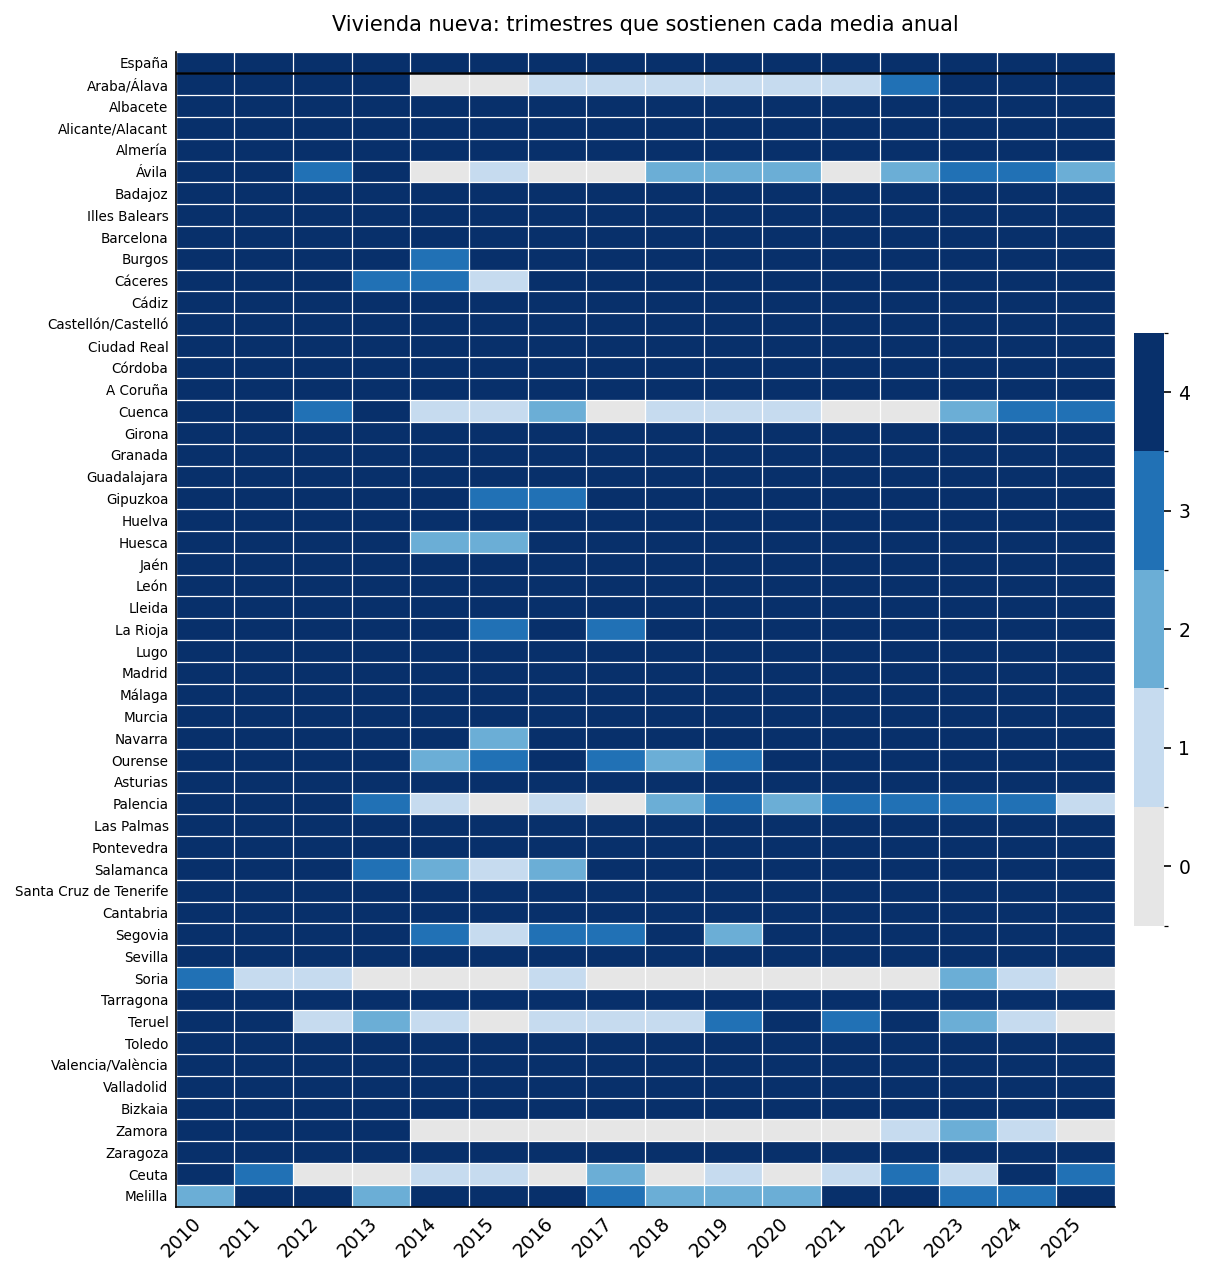

In [6]:
def coverage(kind):
    """Matriz territorio x año con los trimestres que sostienen cada media."""
    wide = panel[panel["kind"] == kind].pivot(
        index="province_code", columns="year", values="quarters_used"
    )
    return wide.reindex(CODES)


def heatmap(matrix, title, path, cmap, norm, ticks, tick_labels, figsize):
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(matrix.values, cmap=cmap, norm=norm, aspect="auto", interpolation="nearest")

    ax.set_xticks(range(matrix.shape[1]))
    ax.set_xticklabels(matrix.columns, rotation=45, ha="right")
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_yticklabels([territory(code) for code in matrix.index], fontsize=6.5)

    # Rejilla fina para separar celdas.
    ax.set_xticks(np.arange(-0.5, matrix.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, matrix.shape[0], 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.6)
    ax.tick_params(which="both", length=0)

    # España arriba, separada de las provincias.
    ax.axhline(0.5, color="black", linewidth=1.2)
    ax.set_title(title, pad=10)

    cbar = fig.colorbar(
        ScalarMappable(norm=norm, cmap=cmap), ax=ax, ticks=ticks, fraction=0.03, pad=0.02
    )
    cbar.ax.set_yticklabels(tick_labels)
    cbar.outline.set_visible(False)

    fig.savefig(path, bbox_inches="tight")
    plt.show()


new_cmap = ListedColormap(["#e6e6e6", "#c6dbef", "#6baed6", "#2171b5", "#08306b"])
heatmap(
    coverage("nueva"),
    "Vivienda nueva: trimestres que sostienen cada media anual",
    FIGURES_DIR / "00_cobertura_nueva.png",
    cmap=new_cmap,
    norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5, 4.5], new_cmap.N),
    ticks=[0, 1, 2, 3, 4],
    tick_labels=["0", "1", "2", "3", "4"],
    figsize=(8.5, 10),
)

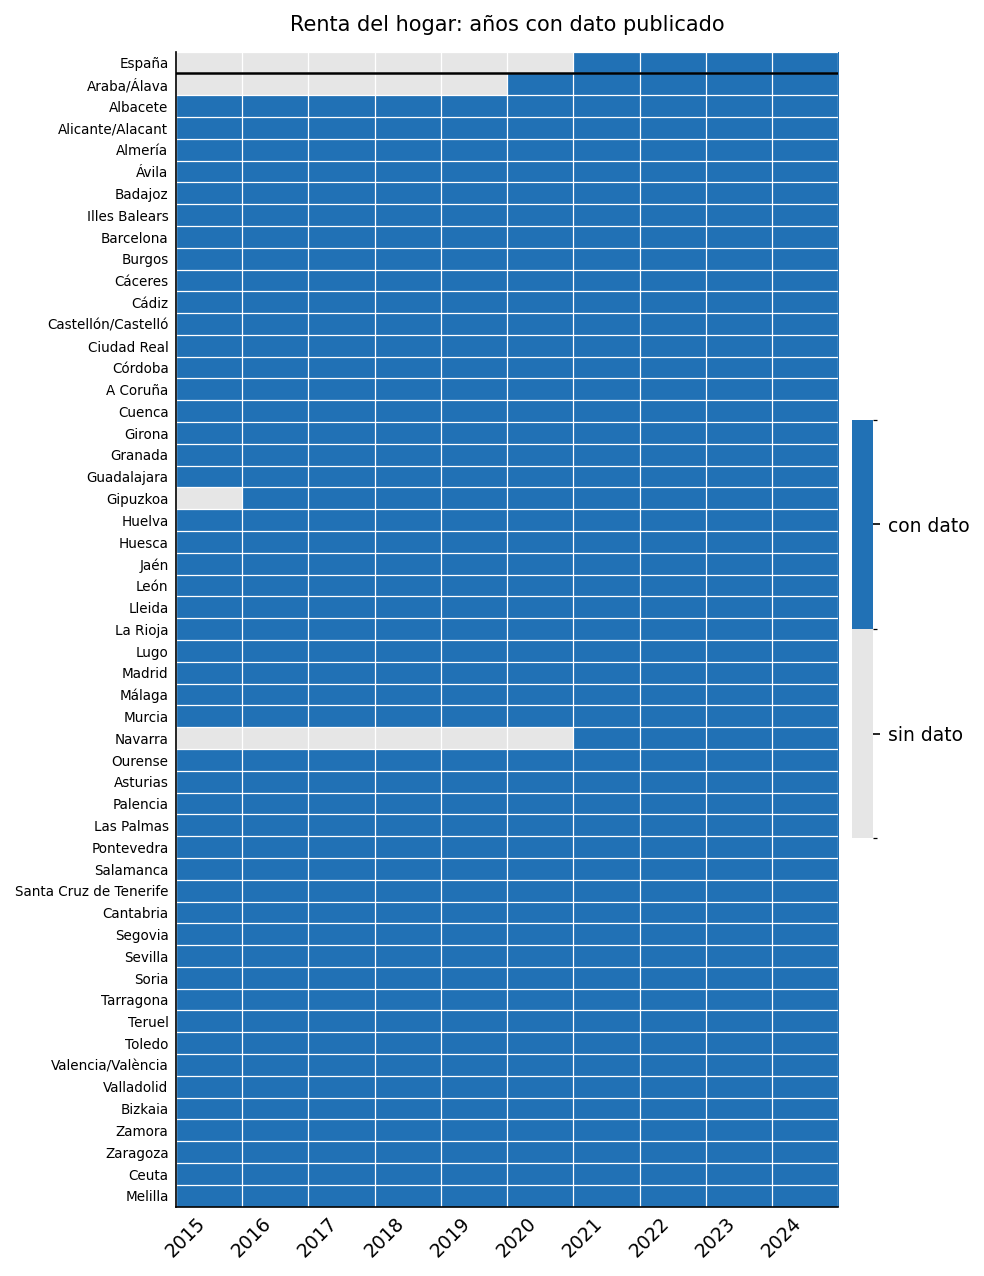

In [7]:
income = (
    panel[panel["kind"] == "total"]
    .pivot(index="province_code", columns="year", values="net_income_household_eur")
    .reindex(CODES)
    .loc[:, list(range(INCOME_START_YEAR, INCOME_END_YEAR + 1))]
    .notna()
    .astype(int)
)

income_cmap = ListedColormap(["#e6e6e6", "#2171b5"])
heatmap(
    income,
    "Renta del hogar: años con dato publicado",
    FIGURES_DIR / "00_cobertura_renta.png",
    cmap=income_cmap,
    norm=BoundaryNorm([-0.5, 0.5, 1.5], income_cmap.N),
    ticks=[0, 1],
    tick_labels=["sin dato", "con dato"],
    figsize=(6, 10),
)

Las dos figuras dicen lo mismo de forma distinta: **la vivienda total es una serie completa y la nueva no**. En la primera, el gris claro no es un año que falte de la serie: es un año publicado en el que ningún trimestre resultó representativo.

## 3 · La métrica

Años de renta neta del hogar necesarios para comprar 90 m². Se calcula en nominal: el IPC iría en el numerador y en el denominador.

In [8]:
metric = panel.dropna(subset=["years_90m2"])
print(f"Filas con métrica (precio y renta a la vez): {len(metric)}")
display(metric.groupby("kind")["years_90m2"].describe().round(2).rename(index=KIND_LABELS))


def table(rows):
    """Extremos con nombre, para que se puedan leer sin cruzar códigos."""
    return pd.DataFrame({
        "territorio": rows["province_code"].map(territory).to_numpy(),
        "año": rows["year"].to_numpy(),
        "tipo": rows["kind"].map(KIND_LABELS).to_numpy(),
        "precio €/m2": rows["price_nominal_eur_m2"].round(0).to_numpy(),
        "renta hogar €": rows["net_income_household_eur"].round(0).to_numpy(),
        "años 90 m2": rows["years_90m2"].round(2).to_numpy(),
    }).set_index("territorio")


print("Máximos:")
display(table(metric.nlargest(5, "years_90m2")))
print("Mínimos:")
display(table(metric.nsmallest(5, "years_90m2")))

Filas con métrica (precio y renta a la vez): 1510


,count,mean,std,min,25%,50%,75%,max
kind,,,,,,,,
Nueva,486.0,4.36,1.06,2.46,3.56,4.21,4.83,7.76
Vivienda total,512.0,3.69,0.96,1.96,3.00,3.50,4.20,6.58
Usada,512.0,3.67,0.96,1.95,2.97,3.48,4.17,6.59


Máximos:


,año,tipo,precio €/m2,renta hogar €,años 90 m2
territorio,,,,,
Gipuzkoa,2017,Nueva,3156.0,36586.0,7.76
Gipuzkoa,2016,Nueva,3033.0,35751.0,7.63
Gipuzkoa,2020,Nueva,3201.0,39023.0,7.38
Gipuzkoa,2018,Nueva,3034.0,37797.0,7.22
Gipuzkoa,2019,Nueva,3122.0,39283.0,7.15


Mínimos:


,año,tipo,precio €/m2,renta hogar €,años 90 m2
territorio,,,,,
Ciudad Real,2024,Usada,718.0,33136.0,1.95
Ciudad Real,2024,Vivienda total,722.0,33136.0,1.96
Teruel,2023,Usada,778.0,34725.0,2.02
Teruel,2023,Vivienda total,791.0,34725.0,2.05
Ciudad Real,2023,Usada,711.0,31095.0,2.06


In [9]:
priced = panel.dropna(subset=["years_70m2", "years_90m2", "years_100m2"])
ordered = (priced["years_70m2"] <= priced["years_90m2"]) & (
    priced["years_90m2"] <= priced["years_100m2"]
)
print(f"70 <= 90 <= 100 m2 en todas las filas: {ordered.all()} ({ordered.sum()} de {len(priced)})")
print(f"Rango de años de renta: {priced['years_90m2'].min():.2f} - {priced['years_90m2'].max():.2f}")

national = metric[metric["province_code"] == NATIONAL_CODE]
print(
    f"Serie nacional con métrica: {national['year'].min()}-{national['year'].max()} "
    f"({national['year'].nunique()} años)"
)

70 <= 90 <= 100 m2 en todas las filas: True (1510 de 1510)
Rango de años de renta: 1.95 - 7.76
Serie nacional con métrica: 2021-2024 (4 años)


In [10]:
# Último año con renta: el ranking que se podrá citar en el resto del EDA.
latest = metric[(metric["year"] == INCOME_END_YEAR) & (metric["kind"] == "total")]
ranking = (
    latest.assign(territorio=latest["province_code"].map(territory))
    .set_index("territorio")
    .sort_values("years_90m2")[["years_90m2"]]
    .rename(columns={"years_90m2": "años de renta"})
    .round(2)
)

print(f"Años de renta para 90 m2, vivienda total, {INCOME_END_YEAR}")
print("\nMás asequibles:")
display(ranking.head(5))
print("Menos asequibles:")
display(ranking.tail(5))

Años de renta para 90 m2, vivienda total, 2024

Más asequibles:


,años de renta
territorio,
Ciudad Real,1.96
Teruel,2.13
Cuenca,2.17
Soria,2.29
León,2.30


Menos asequibles:


,años de renta
territorio,
Barcelona,5.20
Gipuzkoa,5.43
Madrid,5.62
Illes Balears,5.97
Málaga,6.08


## Conclusiones

**El panel sirve para el análisis, con una serie que hay que tratar con cuidado.**

- **Estructura correcta.** 2.703 filas, 53 territorios, 2007–2025, sin claves duplicadas y sin 2026. Las tres series cubren las 52 provincias y el total nacional.
- **Vivienda total y usada son sólidas.** El 99 % de sus medias anuales se apoyan en cuatro trimestres (997 de 1.007 y 846 de 848). Son la base del análisis.
- **Vivienda nueva, no.** 135 de sus 848 filas tienen la media incompleta y 37 no suman ni un trimestre, así que su precio queda nulo. Cualquier gráfico de vivienda nueva tiene que declarar `quarters_used` o filtrar los años flojos.
- **Los huecos de renta son los declarados, ni uno más.** 18 huecos que coinciden exactamente con `ADRH_KNOWN_GAPS` (España y Navarra 2015–2020, Álava 2015–2019, Gipuzkoa 2015). Consecuencia: la serie nacional de años de renta solo existe de 2021 a 2024.
- **La métrica es plausible.** 1.510 filas con precio y renta a la vez, de 1,95 (Ciudad Real 2024, usada) a 7,76 (Gipuzkoa 2017, nueva), y 70 ≤ 90 ≤ 100 m² se cumple siempre. En 2024, vivienda total: de 1,96 en Ciudad Real a 6,08 en Málaga.

Queda fuera de este panel el IPV (solo baja a comunidad autónoma), la renta de 2025–2026 (no publicada, no se extrapola) y el contraste con Registradores. El precio es **valor tasado**, no precio de compraventa.